In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from clustering.utils import generate_data, SpaceTimeSVD, ClusteringCPQR

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 


In [2]:
%matplotlib inline

In [3]:
np.random.seed(0)

In [4]:
data, truth = generate_data(
    n_timepoints=1_000,
    n_components=3,
    noise=0,
    n_pixels=1,
    n_pixels_bg=0
)

In [5]:
data.shape

(3, 2000)

In [6]:
factor = 4

series = np.zeros((9 + 6, 2_000))

In [7]:
series[:3] = data[0]
series[3:6] = data[1]
series[6:9] = data[2]

series[9:12] = data[0] + data[1]
series[12:15] = data[1] + data[2]

In [8]:
series += np.vstack([np.random.normal(scale=10, size=2_000) for i in range(series.shape[0])])

In [9]:
series.shape

(15, 2000)

In [10]:
iw_series = fpl.ImageWidget(series, figure_kwargs={"size": (700, 500)})
iw_series.figure[0, 0].camera.maintain_aspect = False
iw_series.figure[0, 0].set_title("Movie, pixels over time")
iw_series.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='500px', css_width='700px'), IpywidgetToolBar(chil…

In [11]:
iw_series.figure[0, 0].axes.y.ticks = {
    **{k: "1" for k in range(3)},
    **{k: "2" for k in range(3, 6)},
    **{k: "3" for k in range(6, 9)},
    **{k: "1 + 2" for k in range(9, 12)},
    **{k: "2 + 3" for k in range(12, 15)},
}

In [12]:
st_svd = SpaceTimeSVD(series, w=16)
st_svd.compute()

Computing F, P


100%|██████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 18870.59it/s]


(15, 2000)
(120, 1984)


100%|██████████████████████████████████████████████████████████████████████| 15/15 [00:00<00:00, 12143.32it/s]

computing H
Computing Hp
computimng svd of Hp


# $\mathbf{H = FP^T}$

# $\mathbf{H} \in \mathbb{R}^{pw \times pw}$

# Permute elements of H: $\mathbf{H} \rightarrow \mathbf{Hp} \in \mathbb{R}^{w^2 \times p^2}$

# SVD: $\mathbf{USV^T = Hp}$

# Reshape first right singular vector: $\mathbf{V^T} \rightarrow \mathbf{B} \in \mathbb{R}^{p \times p}$

In [13]:
iw_adj = fpl.ImageWidget(st_svd.adjacency)
iw_adj.figure[0, 0].set_title("B, adjacency")
iw_adj.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

# $\mathbf{B} \approx \mathbf{B}^T$

# Force B to be symmetric $\mathbf{B'} = \frac{\mathbf{B + B^T}}{2}$

In [14]:
B = st_svd.adjacency
B = (B + B.T) / 2

# Eigendecomposition: $\mathbf{B'= QDQ^T}$
# $\mathbf{Q} \in \mathbb{R}^{p \times p}, \mathbf{Q^{-1} = Q^T}$

### Take the first `k` columns of **Q**, these eigenvectors will be used for clustering

# $\mathbf{Q_k} \in \mathbb{R}^{p \times k}$

# $\mathbf{Q_k^T} \in \mathbb{R}^{k \times p}$

# Normalize rows of $\mathbf{Q_K^T}$

In [15]:
k = 3

In [16]:
evals, Qk = np.linalg.eigh(st_svd.adjacency)

In [17]:
iw_Qk = fpl.ImageWidget(Qk, cmap="seismic")
iw_Qk.figure[0, 0].set_title("Qk")
iw_Qk.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [18]:
from scipy.linalg import interpolative

In [35]:
ixs, proj = interpolative.interp_decomp(Qk.T[:k], eps_or_k=k)

In [36]:
proj.T.shape

(12, 3)

In [37]:
def basis_vect_swap(a, idx, c, w, ind_old, ind_new):
    """
    given the interpolative decomposition A = C * W,
    we swap the basis vector (column of C) that is column ind_old
    of A with the basis vector that is column ind_new of A.

    NB: this code is inefficient and can be optimized in many ways.

    Parameters
    ----------
    a: k x n numpy array
        matrix of which we have the interpolative decomposition
    idx: array of length k
        indices of the k basis vectors
    c: k x k numpy array
        matrix of basis vectors (column-wise)
    w: k x n numpy array
        interpolation matrix
    ind_old: int
        the index of the basis vector to be replaced
    ind_new: int
        the index of the new basis vector

    Returns
    -------
    cnew: k x k numpy array
        new matrix of basis vectors
    wnew: k x n numpy array
        new interpolation matrix
    idx_new: array of length k
        new indices of basis vectors

    """
    k = c.shape[1]

    # choose some basis vector to replace
    v_old = a[:, ind_old]
    # its the interpolation matrix
    c_ind_old = np.where(idx == ind_old)[0][0]

    # choose new basis vector
    v_old = a[:, ind_old]
    v_new = a[:, ind_new]

    # construct new c (matrix with basis columns)
    cnew = c.copy()
    cnew[:, c_ind_old] = v_new

    # and new w
    wnew = np.linalg.inv(cnew) @ c  @ w

    idx_new = idx.copy()
    idx_new[c_ind_old] = ind_new

    # and check accuracy
    if not np.allclose(a, cnew @ wnew):
        raise ValueError

    return cnew, wnew, idx_new

In [38]:
C = Qk.T[:k][:, ixs[:k]]
C_ixs = ixs[:k]

W = np.hstack([np.eye(k), proj])[:, np.argsort(ixs)]

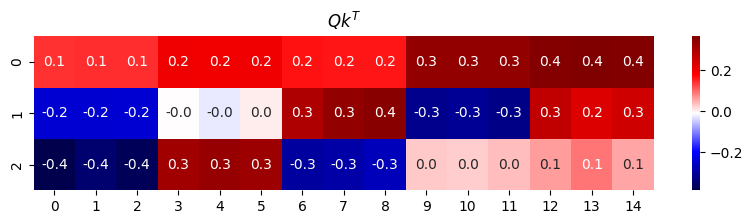

In [39]:
fig = plt.figure(figsize=(10, 2))
sns.heatmap(Qk.T[:k], annot=True, fmt="0.1f", cmap="seismic")
plt.title("$Qk^T$")
plt.show()

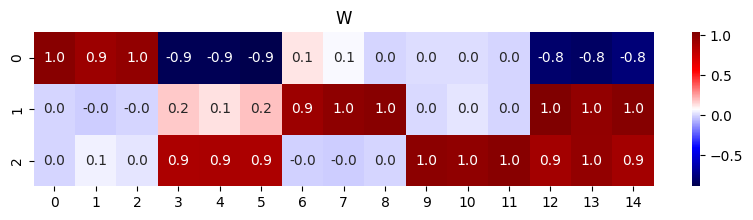

In [95]:
fig = plt.figure(figsize=(10, 2))
sns.heatmap(W, annot=True, fmt="0.1f", cmap="seismic")
plt.title("W")
plt.show()

In [71]:
def get_bases_to_swap(W_, C_ixs_, negs_exclude_ix: int = None) -> tuple[int, int]:
    """
    returns: old_ix, new_ix
    """
    # choose a random basis
    basis_old = np.random.choice(C_ixs_, size=1).item()

    negs = np.argwhere(W_ < -0.20)[:, 1]
    
    if negs_exclude_ix:
        # exclude an index that has already been tried before
        negs = negs[negs != negs_exclude_ix]
        
    negs_in_C_ixs = np.intersect1d(negs, C_ixs_, return_indices=True)[1]

    mask = np.ones(len(negs), bool)
    mask[negs_in_C_ixs] = False
    
    negs = negs[mask]
    
    # choose random column with negative to be new basis
    basis_new = np.random.choice(negs, size=1).item()

    return basis_old, basis_new

In [72]:
from tqdm import tqdm

In [91]:
Ws = list()
niter = 10

C_ = C.copy()
W_ = W.copy()
C_ixs_ = C_ixs.copy()

for i in tqdm(range(niter)):
    basis_old, basis_new = get_bases_to_swap(W_, C_ixs_)
    
    C2, W2, C_ixs2 = basis_vect_swap(Qk.T[:k], C_ixs_, C_, W_, basis_old, basis_new)
    # check if W2 is more non-negative than W_
    if (W2 < -0.25).sum() < (W_ < -0.15).sum():
        W_ = W2
        C_ = C2
        C_ixs_ = C_ixs2
        Ws.append(W_)
    else:
        # pick different columns, exclude one we already tried
        basis_old, basis_new = get_bases_to_swap(W_, C_ixs_, negs_exclude_ix=basis_new)
    # no more non-negative element, we're done :D !!
    if (W2 < -0.25).sum() < 1:
        break

  0%|                                                                                  | 0/10 [00:00<?, ?it/s]


In [93]:
basis_old

11

In [94]:
basis_new

4

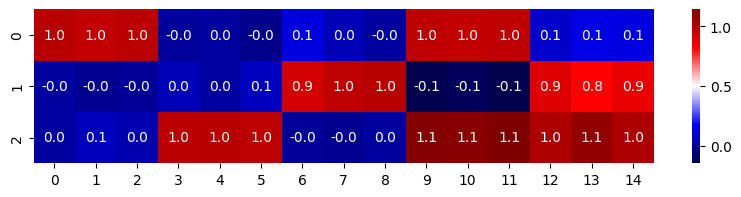

In [92]:
fig = plt.figure(figsize=(10, 2))
sns.heatmap(W_, annot=True, fmt="0.1f", cmap="seismic")
plt.show()

In [26]:
fig_proj = fpl.Figure(cameras="3d", controller_types="orbit", size=(750, 550))
colors = np.array(["r", "r", "r", "g", "g", "g", "cyan", "cyan", "cyan", "y", "y", "y", "w", "w", "w"])
scatter = fig_proj[0, 0].add_scatter(W.T, sizes=15, colors=colors, alpha=0.4)
fig_proj[0, 0].set_title("W, projection")
# scatter[:15].colors = colors


fig_proj[0, 0].axes.intersection = (0, 0, 0)
fig_proj.show(sidecar=True)

c1 = fig_proj[0, 0].graphics[0].data[0]
c2 = fig_proj[0, 0].graphics[0].data[3]
c3 = fig_proj[0, 0].graphics[0].data[6]
c1_2 = fig_proj[0, 0].graphics[0].data[9]
c2_3 = fig_proj[0, 0].graphics[0].data[12]

fig_proj[0, 0].add_text("C: 1", offset=(c1[0] + 0.2, *c1[1:]), font_size=24)
fig_proj[0, 0].add_text("C: 2", offset=(c2[0] + 0.2, *c2[1:]), font_size=24)
fig_proj[0, 0].add_text("C: 3", offset=(c3[0] + 0.2, *c3[1:]), font_size=24)

fig_proj[0, 0].add_text("C: 1+2", offset=(c1_2[0] + 0.2, *c1_2[1:]), font_size=24)
fig_proj[0, 0].add_text("C: 2+3", offset=(c2_3[0] + 0.2, *c2_3[1:]), font_size=24)

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:276: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


TextGraphic @ 0x7f1a4ce44710

In [96]:
C_new, W_new, C_ixs_new = basis_vect_swap(Qk.T[:k], C_ixs, C, W, 11, 4)

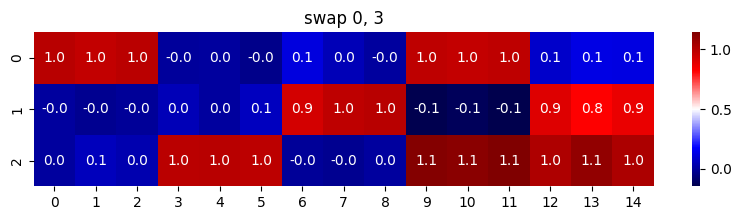

In [97]:
fig = plt.figure(figsize=(10, 2))
sns.heatmap(W_new, annot=True, fmt="0.1f", cmap="seismic")
plt.title("swap 0, 3")
plt.show()

In [34]:
C_ixs_new

array([ 3,  8, 11], dtype=int32)

In [43]:
C2_new, W2_new, C2_ixs_new = basis_vect_swap(Qk.T[:k], C_ixs_new, C_new, W_new, 11, 0)

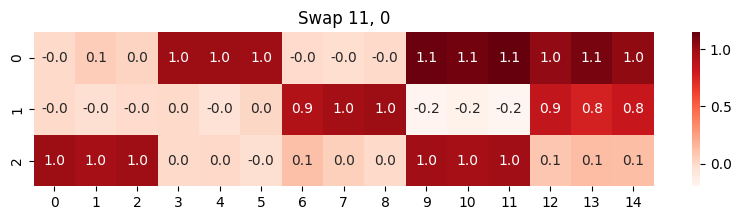

In [44]:
fig = plt.figure(figsize=(10, 2))
sns.heatmap(W2_new, annot=True, fmt="0.1f", cmap="Reds")
plt.title("Swap 11, 0")
plt.show()

In [116]:
(W2_new < -0.25).sum()

np.int64(0)

In [31]:
fig_proj = fpl.Figure(cameras="3d", controller_types="orbit", size=(750, 550))
colors = np.array(["r", "r", "r", "g", "g", "g", "cyan", "cyan", "cyan", "y", "y", "y", "w", "w", "w"])
fig_proj[0, 0].add_scatter(W2_new.T, sizes=15, colors=colors, alpha=0.4)
fig_proj[0, 0].set_title("W, after swapping")

fig_proj[0, 0].axes.intersection = (0, 0, 0)
fig_proj.show(sidecar=True)

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:276: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [32]:
c1 = fig_proj[0, 0].graphics[0].data[0]
c2 = fig_proj[0, 0].graphics[0].data[3]
c3 = fig_proj[0, 0].graphics[0].data[6]
c1_2 = fig_proj[0, 0].graphics[0].data[9]
c2_3 = fig_proj[0, 0].graphics[0].data[12]

In [33]:
fig_proj[0, 0].add_text("C: 1", offset=(c1[0] + 0.2, *c1[1:]), font_size=24)
fig_proj[0, 0].add_text("C: 2", offset=(c2[0] + 0.2, *c2[1:]), font_size=24)
fig_proj[0, 0].add_text("C: 3", offset=(c3[0] + 0.2, *c3[1:]), font_size=24)

fig_proj[0, 0].add_text("C: 1+2", offset=(c1_2[0] + 0.2, *c1_2[1:]), font_size=24)
fig_proj[0, 0].add_text("C: 2+3", offset=(c2_3[0] + 0.2, *c2_3[1:]), font_size=24)

TextGraphic @ 0x7f1a4c865090